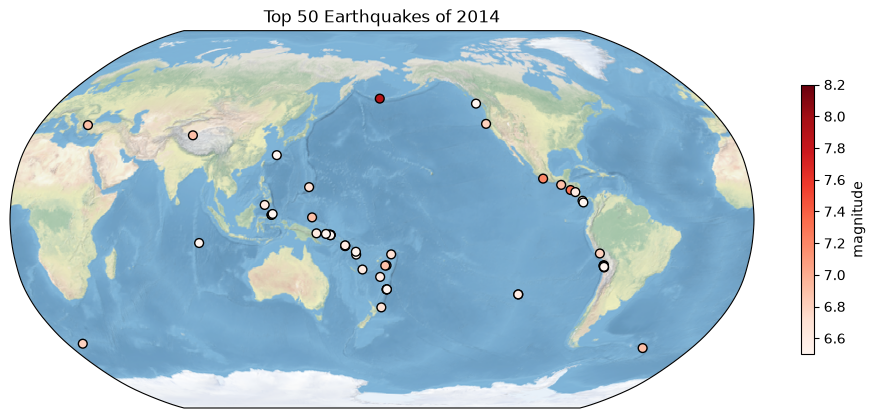

In [18]:
#problem 1
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
eq=pd.read_csv("usgs_earthquakes.csv")

#calculate the top 50
eq50=eq.sort_values('mag',ascending=False).head(50)

#canvas
plt.figure(figsize=(12,5),dpi=100)

#设定投影系和中心点
proj=ccrs.Robinson(central_longitude=180)
ax=plt.axes(projection=proj)
ax.stock_img()
#增加圆点的边缘,设置颜色，和转换坐标
a=ax.scatter(eq50['longitude'],eq50['latitude'],c=eq50['mag'],s=40,edgecolors='black',cmap='Reds',transform=ccrs.PlateCarree())
#补充图名和图列
plt.title('Top 50 Earthquakes of 2014')
plt.colorbar(a,ax=ax,label='magnitude',shrink=0.7)

plt.show()

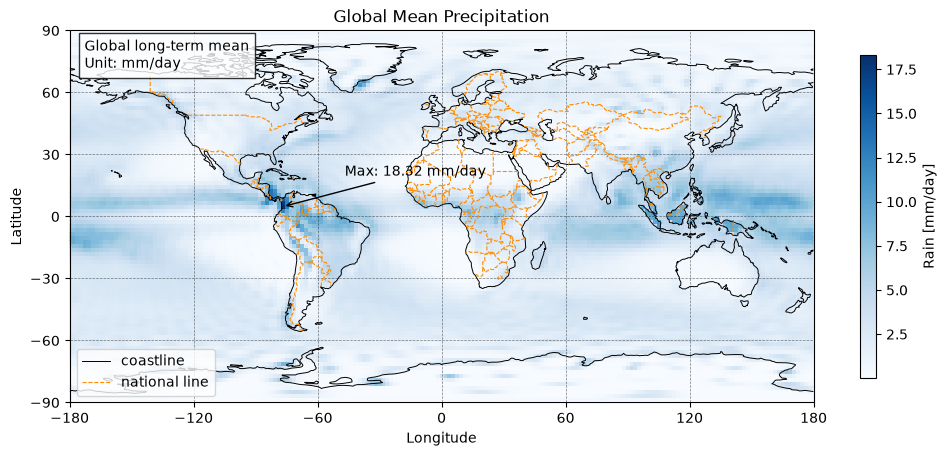

In [19]:
#problem 2.1
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import netCDF4
import xarray as xr
pro3 = xr.open_dataset("prate.sfc.mon.mean.nc", engine="netcdf4")
pro3['prate']=pro3.prate*86400
rain=pro3.prate.mean(dim='time')

plt.figure(figsize=(12,6),dpi=100)

#设置地图投影
proj=ccrs.PlateCarree()
ax=plt.axes(projection=proj)
ax.set_global()
ax.coastlines(linewidth=0.7,zorder=2)

p=rain.plot(ax=ax,transform=ccrs.PlateCarree(),cmap='Blues',add_colorbar=False)

#设置X轴
ax.set_xticks(np.arange(-180,181,60),crs=ccrs.PlateCarree())
ax.set_xlabel('Longitude')
#设置Y轴
ax.set_yticks(np.arange(-90,91,30),crs=ccrs.PlateCarree())
ax.set_ylabel('Latitude')
#添加标题
plt.title('Global Mean Precipitation')
#添加经纬度网格线
ax.gridlines(linestyle='--',linewidth=0.5,color='black',alpha=0.5)
#图例
ax.plot([],[],color='black',linestyle='-',linewidth=0.7,label='coastline')
ax.plot([],[],color='darkorange',linestyle='--',linewidth=0.8,label='national line')
ax.legend(loc='lower left')
#颜色条
plt.colorbar(p,ax=ax,label='Rain [mm/day]',shrink=0.7)
#对于masks or features，添加了国界线
ax.add_feature(cfeature.BORDERS,edgecolor='darkorange',linewidth=0.8,linestyle='--',zorder=3)
#添加标注，指明最大降雨
m=rain.where(rain==rain.max(),drop=True)
lon=float(m.lon.values[0])
lat=float(m.lat.values[0])
value=float(m.max().values)
ax.annotate('Max: '+str(round(value,2))+' mm/day',xy=(lon,lat),xytext=(lon+30,lat+15),arrowprops={'arrowstyle':'->'})
#添加文本框，说明数据内容和单位
ax.text(0.02,0.90,'Global long-term mean\nUnit: mm/day',transform=ax.transAxes,bbox={'facecolor':'white','edgecolor':'black','alpha':0.8})

plt.show()

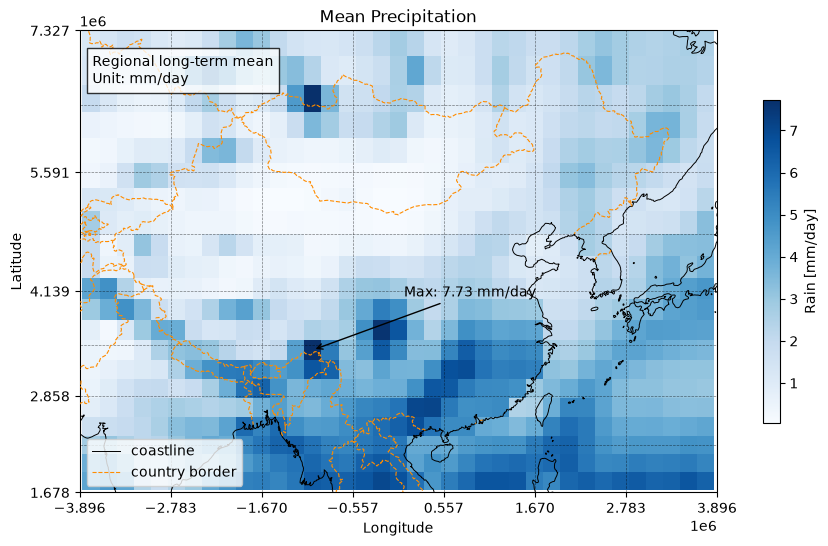

In [20]:
#problem 2.2
pro3=xr.open_dataset("prate.sfc.mon.mean.nc",engine="netcdf4")
pro3['prate']=pro3.prate*86400
rain=pro3.prate.mean(dim='time')
china=rain.sel(lon=slice(70,140),lat=slice(55,15))

plt.figure(figsize=(12,6),dpi=100)
# 设置地图投影
proj=ccrs.Mercator(central_longitude=105)
ax=plt.axes(projection=proj)
ax.set_extent([70,140,15,55],crs=ccrs.PlateCarree())
ax.coastlines(linewidth=0.7,zorder=2)
p=china.plot(ax=ax,transform=ccrs.PlateCarree(),cmap='Blues',add_colorbar=False)
# 设置X轴
ax.set_xticks(np.arange(70,141,10),crs=ccrs.PlateCarree())
ax.set_xlabel('Longitude')
# 设置Y轴
ax.set_yticks(np.arange(15,56,10),crs=ccrs.PlateCarree())
ax.set_ylabel('Latitude')
# 添加标题
plt.title('Mean Precipitation')
# 添加网格线
ax.gridlines(crs=ccrs.PlateCarree(),linestyle='--',linewidth=0.5,color='black',alpha=0.5)
# 添加图例
ax.plot([],[],color='black',linestyle='-',linewidth=0.7,label='coastline')
ax.plot([],[],color='darkorange',linestyle='--',linewidth=0.8,label='country border')
ax.legend(loc='lower left')
# 添加颜色条
plt.colorbar(p,ax=ax,label='Rain [mm/day]',shrink=0.7)
# 添加国界线
ax.add_feature(cfeature.BORDERS,edgecolor='darkorange',linewidth=0.8,linestyle='--',zorder=3)
# 标注区域内最大降雨值的位置
m=china.where(china==china.max(),drop=True)
lon=float(m.lon.values[0])
lat=float(m.lat.values[0])
value=float(m.max().values)
ax.annotate('Max: '+str(round(value,2))+' mm/day',xy=(lon,lat),xytext=(lon+10,lat+5),transform=ccrs.PlateCarree(),arrowprops={'arrowstyle':'->'})
# 添加文本框
ax.text(0.02,0.95,'Regional long-term mean\nUnit: mm/day',transform=ax.transAxes,verticalalignment='top'
        ,bbox={'facecolor':'white','edgecolor':'black','alpha':0.8})
plt.show()